# CAP4453 Assignment 4 · Vision Transformer on CIFAR-10

**Xavier Andres Soto Baron**

This notebook compares ViTs with two and four encoder blocks on native 32×32 CIFAR-10 images. Both models use the same training settings. Each model is evaluated on the test set once, after selecting its checkpoint by validation accuracy.

## 1) Setup & Environment

In [1]:
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42

def seed_run():
    """Reset the random streams before training each depth."""
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

seed_run()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
amp_dtype = torch.bfloat16 if use_amp and torch.cuda.is_bf16_supported() else torch.float16
run_dir = Path('vit_results')
run_dir.mkdir(exist_ok=True)
hardware = torch.cuda.get_device_name(0) if use_amp else 'CPU'
precision = str(amp_dtype).removeprefix('torch.') + ' autocast' if use_amp else 'float32'
print(f'Device: {hardware} | PyTorch {torch.__version__} | Training: {precision}')

Device: NVIDIA GeForce RTX 5050 Laptop GPU | PyTorch 2.14.0+cu130 | Training: bfloat16 autocast


## 2) CIFAR‑10 Data & Transforms (32×32)

**Fixed setup (no tuning):**
- We use native **32×32** CIFAR‑10 images.
- We use a **standard CIFAR‑10 augmentation** for training (crop + flip) and deterministic transforms for validation/test.
- A **fixed train/val split** is created with a seed for reproducibility.

You do **not** need to change transforms or split settings for this assignment.


In [2]:
# Fixed data settings
DATA_DIR    = './data'
NUM_WORKERS = 2
IMAGE_SIZE  = 32
VAL_RATIO   = 0.1

# CPU-friendly defaults (auto-adjust)
if torch.cuda.is_available():
    BATCH_SIZE = 128
else:
    BATCH_SIZE = 64

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

# Augmentation is applied only to the training split.
train_tfms = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

val_test_tfms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

# Load the training partition with each transform pipeline.
train_ds_full = datasets.CIFAR10(root=DATA_DIR, train=True,  download=True, transform=train_tfms)
val_ds_full   = datasets.CIFAR10(root=DATA_DIR, train=True,  download=False, transform=val_test_tfms)
test_ds       = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=val_test_tfms)

# Split one seeded permutation into disjoint index sets.
n_total = len(train_ds_full)
n_val   = int(n_total * VAL_RATIO)
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(n_total, generator=g).tolist()
val_idx   = perm[:n_val]
train_idx = perm[n_val:]

train_ds = torch.utils.data.Subset(train_ds_full, train_idx)
val_ds   = torch.utils.data.Subset(val_ds_full,   val_idx)

loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=use_amp)
val_loader = DataLoader(val_ds, **loader_options, persistent_workers=NUM_WORKERS > 0)
test_loader = DataLoader(test_ds, **loader_options)
print(f'Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)} | Batch size: {BATCH_SIZE}')

Train: 45000 | Val: 5000 | Test: 10000 | Batch size: 128


## 3) Vision Transformer (ViT) Components — Configurable Depth

Implement a minimal ViT with a configurable encoder **depth** (number of Transformer blocks).

Architecture:
1. **Patch embedding**: `Conv2d(in_ch, EMBED_DIM, kernel_size=PATCH_SIZE, stride=PATCH_SIZE)` → flatten into tokens.
2. **[CLS] token + positional embeddings**: prepend a learnable class token; add learnable positional encodings.
3. **Transformer encoder blocks (× depth)**: LayerNorm → Multi‑Head Self‑Attention → residual → LayerNorm → MLP → residual.
4. **Classifier head**: use the [CLS] token → linear layer to 10 classes.

In [3]:
class PatchEmbed(nn.Module):
    """Project nonoverlapping image patches into token vectors."""

    def __init__(self, in_ch: int, embed_dim: int, patch_size: int):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Flatten the patch grid and move the embedding dimension last.
        return self.proj(x).flatten(2).transpose(1, 2)

In [4]:
class TransformerEncoderBlock(nn.Module):
    """Mix tokens with attention, then transform each token with an MLP."""

    def __init__(self, embed_dim: int, num_heads: int, mlp_ratio: float = 4.0, dropout: float = 0.0):
        super().__init__()
        self.ln1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        self.ln2 = nn.LayerNorm(embed_dim)
        hidden = int(embed_dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, embed_dim),
            nn.Dropout(dropout),
        )
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = self.ln1(x)
        attended, _ = self.attn(z, z, z, need_weights=False)
        x = x + self.drop(attended)
        return x + self.mlp(self.ln2(x))

In [5]:
class ViT(nn.Module):
    """Classify an image from the final class token representation."""

    def __init__(self, image_size: int, patch_size: int, in_chans: int,
                 num_classes: int, embed_dim: int, num_heads: int, mlp_ratio: float,
                 depth: int, dropout: float = 0.0):
        super().__init__()
        assert image_size % patch_size == 0, 'image_size must be divisible by patch_size'
        self.num_patches = (image_size // patch_size) ** 2
        self.patch_embed = PatchEmbed(in_chans, embed_dim, patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 1 + self.num_patches, embed_dim))
        self.pos_drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(
            TransformerEncoderBlock(embed_dim, num_heads, mlp_ratio, dropout)
            for _ in range(depth)
        )
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        patches = self.patch_embed(x)
        cls = self.cls_token.expand(patches.size(0), -1, -1)
        tokens = self.pos_drop(torch.cat((cls, patches), dim=1) + self.pos_embed)
        for block in self.blocks:
            tokens = block(tokens)
        return self.head(self.norm(tokens)[:, 0])

## 4) ViT Hyper‑Parameters (fixed; depth varies)

To reduce workload and keep runtime reasonable, this assignment uses **fixed** ViT settings.

You will run **two depths only**:
- **DEPTH = 2**
- **DEPTH = 4**

Do **not** change other hyper‑parameters unless instructed by the course staff.


In [6]:
# Fixed ViT hyper-parameters (no tuning)
PATCH_SIZE  = 4
EMBED_DIM   = 128
NUM_HEADS   = 4
MLP_RATIO   = 4.0
DROPOUT     = 0.1
NUM_CLASSES = 10

def make_vit(depth: int) -> nn.Module:
    """Factory for ViT models at a given depth."""
    return ViT(
        image_size=IMAGE_SIZE,
        patch_size=PATCH_SIZE,
        in_chans=3,
        num_classes=NUM_CLASSES,
        embed_dim=EMBED_DIM,
        num_heads=NUM_HEADS,
        mlp_ratio=MLP_RATIO,
        depth=depth,
        dropout=DROPOUT,
    )


## 5) Optimiser / Loss (fixed; no tuning)

We use a standard configuration for ViT training on CIFAR‑10:
- Optimiser: **AdamW**
- Loss: **Cross‑Entropy**

These settings are fixed in the notebook to avoid hyper‑parameter tuning.


In [7]:
# Training configuration (fixed; no tuning)
if torch.cuda.is_available():
    EPOCHS = 20
else:
    EPOCHS = 10

BASE_LR      = 3e-4
WEIGHT_DECAY = 0.05
BETAS        = (0.9, 0.999)
GRAD_CLIP    = 1.0  # keep training stable; set to None to disable

criterion = nn.CrossEntropyLoss()

def make_optimizer(model: nn.Module):
    return torch.optim.AdamW(model.parameters(), lr=BASE_LR, weight_decay=WEIGHT_DECAY, betas=BETAS, fused=use_amp)


## 6) Training & Evaluation

Each depth starts from seed 42 and uses its own identically seeded training loader. CUDA training uses mixed precision, while validation and test use float32. The earliest epoch with the highest validation accuracy is saved. Its single test pass also collects eight misclassified images for display.

In [8]:
def train_one_epoch(model, loader, optimizer, scaler):
    """Update the model and accumulate sample-weighted training metrics."""
    model.train()
    total_loss = torch.zeros((), device=device)
    total_correct = torch.zeros((), dtype=torch.long, device=device)
    total_n = 0

    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()

        if GRAD_CLIP is not None:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)

        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.detach() * y.size(0)
        total_correct += (logits.detach().argmax(dim=1) == y).sum()
        total_n += y.size(0)

    return total_loss.item() / total_n, 100 * total_correct.item() / total_n


@torch.no_grad()
def evaluate(model, loader, mistakes=None, max_images=8):
    """Measure accuracy and optionally retain errors from the same pass."""
    model.eval()
    total_loss = torch.zeros((), device=device)
    total_correct = torch.zeros((), dtype=torch.long, device=device)
    total_n = 0

    for x, y in loader:
        logits = model(x.to(device, non_blocking=True))
        labels = y.to(device, non_blocking=True)
        pred = logits.argmax(dim=1)
        total_loss += criterion(logits, labels) * y.size(0)
        total_correct += (pred == labels).sum()

        if mistakes is not None and len(mistakes) < max_images:
            pred_cpu = pred.cpu()
            wrong = (pred_cpu != y).nonzero(as_tuple=True)[0]
            for i in wrong[:max_images - len(mistakes)].tolist():
                mistakes.append((x[i].clone(), pred_cpu[i].item(), y[i].item(), total_n + i))
        total_n += y.size(0)

    return total_loss.item() / total_n, 100 * total_correct.item() / total_n


def plot_curves(history, title):
    """Display the training and validation traces for one depth."""
    epochs = np.arange(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')
    for ax, key, label in zip(axes, ('loss', 'acc'), ('Cross-entropy loss', 'Accuracy (%)')):
        ax.plot(epochs, history[f'train_{key}'], label='Train')
        ax.plot(epochs, history[f'val_{key}'], label='Validation')
        ax.set(xlabel='Epoch', ylabel=label)
        ax.legend()
        ax.grid(alpha=0.2)
    fig.suptitle(title)
    plt.show()


def run_experiment(depth: int, tag: str):
    """Train one depth, reload its best validation checkpoint, and test once."""
    seed_run()
    train_loader = DataLoader(train_ds, **loader_options, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED),
                              persistent_workers=NUM_WORKERS > 0)
    model = make_vit(depth).to(device)
    optimizer = make_optimizer(model)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp and amp_dtype == torch.float16)
    history = {key: [] for key in ('train_loss', 'train_acc', 'val_loss', 'val_acc')}
    best_val_acc, best_epoch = -1.0, 0
    ckpt_path = run_dir / f'best_vit_{tag}.pt'
    t0 = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scaler)
        va_loss, va_acc = evaluate(model, val_loader)
        for key, value in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[key].append(value)

        if va_acc > best_val_acc:
            best_val_acc, best_epoch = va_acc, epoch
            best_state = {key: value.detach().cpu() for key, value in model.state_dict().items()}
            torch.save({'depth': depth, 'epoch': epoch, 'state_dict': best_state}, ckpt_path)

        print(f'[{tag}] epoch {epoch:02d}/{EPOCHS} | train {tr_loss:.4f}, {tr_acc:.2f}% '
              f'| val {va_loss:.4f}, {va_acc:.2f}%', flush=True)

    elapsed = time.perf_counter() - t0
    checkpoint = torch.load(ckpt_path, map_location='cpu', weights_only=True)
    model.load_state_dict(checkpoint['state_dict'])
    mistakes = []
    test_loss, test_acc = evaluate(model, test_loader, mistakes=mistakes)

    results = dict(tag=tag, depth=depth, best_epoch=best_epoch, best_val_acc=best_val_acc,
                   best_val_loss=history['val_loss'][best_epoch - 1], test_acc=test_acc,
                   test_loss=test_loss, ckpt_path=str(ckpt_path), history=history,
                   parameters=sum(p.numel() for p in model.parameters()), seconds=elapsed)
    print(f'[{tag}] {elapsed / 60:.1f} min | Best epoch {best_epoch} | '
          f'Validation {best_val_acc:.2f}% | Test {test_acc:.2f}%')
    return results, mistakes

## 7) Experiment A — DEPTH = 2

Run a single training run with **DEPTH=2**.  
The notebook will automatically keep the **best epoch by validation accuracy** and then evaluate once on the test set.


[depth2] epoch 01/20 | train 1.8045, 32.77% | val 1.5954, 41.68%


[depth2] epoch 02/20 | train 1.5356, 43.55% | val 1.4354, 49.06%


[depth2] epoch 03/20 | train 1.4102, 48.69% | val 1.2897, 53.82%


[depth2] epoch 04/20 | train 1.3324, 51.80% | val 1.2662, 54.72%


[depth2] epoch 05/20 | train 1.2885, 53.12% | val 1.1780, 58.38%


[depth2] epoch 06/20 | train 1.2433, 54.99% | val 1.1480, 58.46%


... (11 outputs left out)

[depth2] epoch 18/20 | train 0.9836, 64.66% | val 0.9167, 67.12%


[depth2] epoch 19/20 | train 0.9699, 65.04% | val 0.9042, 68.44%


[depth2] epoch 20/20 | train 0.9549, 65.61% | val 0.8920, 68.48%


[depth2] 4.2 min | Best epoch 20 | Validation 68.48% | Test 67.20%


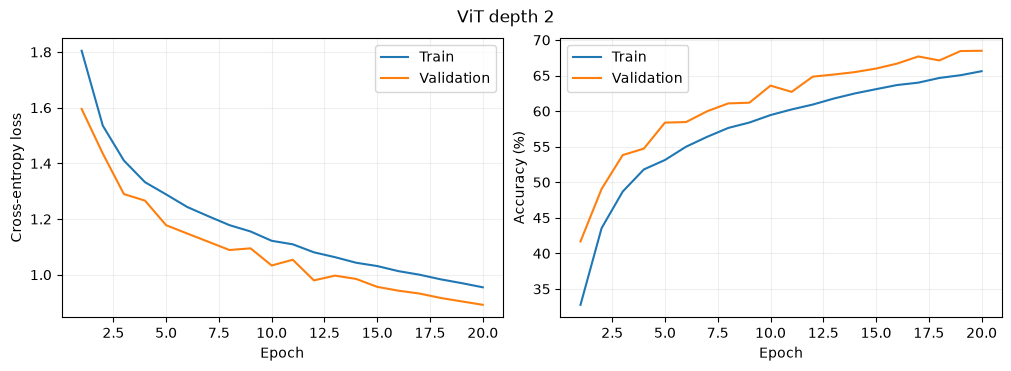

In [9]:
results_d2, mistakes_d2 = run_experiment(depth=2, tag='depth2')
plot_curves(results_d2['history'], title='ViT depth 2')

## 8) Experiment B — DEPTH = 4

Run a single training run with **DEPTH=4** using the **same fixed settings**.  
Again, select the best checkpoint by validation accuracy and evaluate once on the test set.


[depth4] epoch 01/20 | train 1.7943, 32.82% | val 1.6559, 40.16%


[depth4] epoch 02/20 | train 1.5346, 43.49% | val 1.4375, 47.90%


[depth4] epoch 03/20 | train 1.3973, 49.06% | val 1.2946, 53.04%


[depth4] epoch 04/20 | train 1.3000, 52.69% | val 1.3054, 53.32%


[depth4] epoch 05/20 | train 1.2395, 54.77% | val 1.1506, 58.98%


[depth4] epoch 06/20 | train 1.1848, 57.38% | val 1.0858, 61.10%


... (11 outputs left out)

[depth4] epoch 18/20 | train 0.8375, 70.12% | val 0.7868, 72.64%


[depth4] epoch 19/20 | train 0.8232, 70.78% | val 0.7661, 73.48%


[depth4] epoch 20/20 | train 0.8014, 71.50% | val 0.7611, 73.34%


[depth4] 4.1 min | Best epoch 19 | Validation 73.48% | Test 72.60%


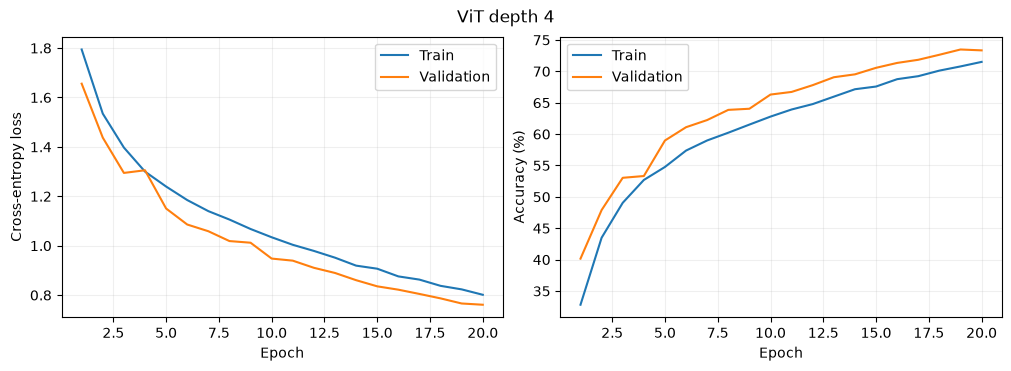

In [10]:
results_d4, mistakes_d4 = run_experiment(depth=4, tag='depth4')
plot_curves(results_d4['history'], title='ViT depth 4')

## 9) Comparison Summary

The table reports the selected epoch, its validation accuracy, and the test accuracy obtained after reloading that checkpoint.

In [11]:
print(f"{'Depth':>5}  {'Best epoch':>10}  {'Best val accuracy':>17}  {'Test accuracy':>13}")
for result in (results_d2, results_d4):
    print(f"{result['depth']:>5}  {result['best_epoch']:>10}  "
          f"{result['best_val_acc']:>16.2f}%  {result['test_acc']:>12.2f}%")

metadata = dict(device=hardware, torch=torch.__version__, precision=precision, seed=SEED,
                batch_size=BATCH_SIZE, epochs=EPOCHS)
(run_dir / 'metrics.json').write_text(json.dumps({
    'run': metadata, 'experiments': [results_d2, results_d4],
}, indent=2), encoding='utf-8')

Depth  Best epoch  Best val accuracy  Test accuracy
    2          20             68.48%         67.20%
    4          19             73.48%         72.60%


5275

## 10) Misclassified Test Examples

Each grid shows the first eight errors collected during the corresponding test pass. Image numbers are zero-based CIFAR-10 test indices.

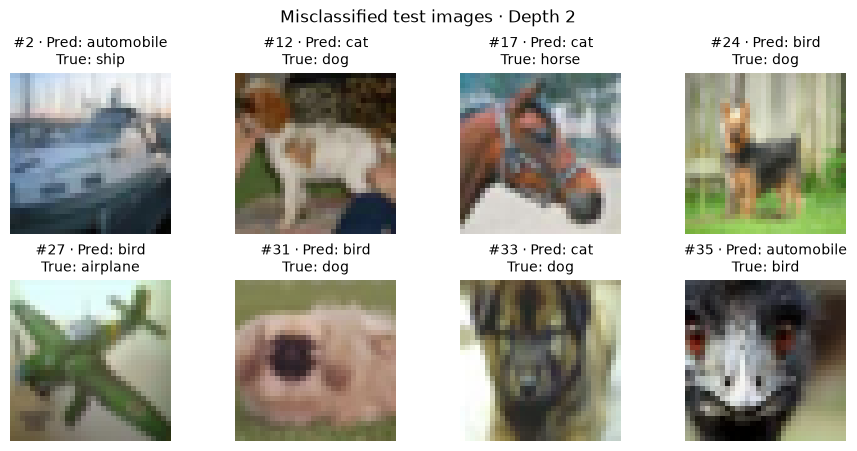

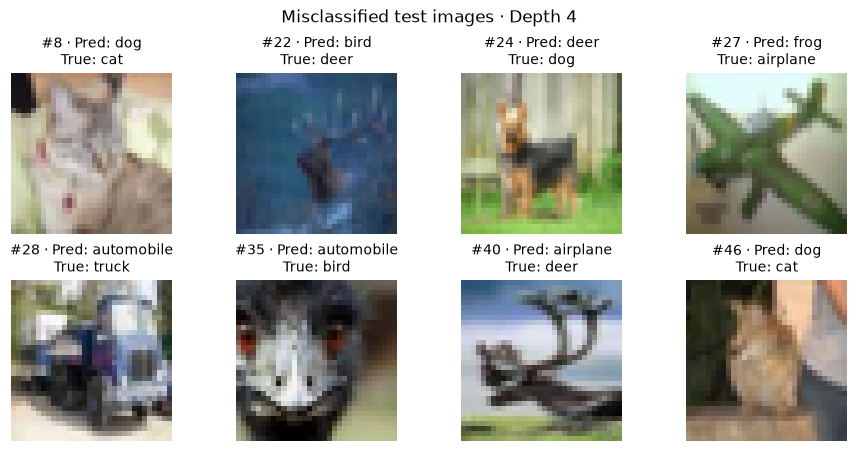

In [12]:
CLASSES = test_ds.classes
mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std = torch.tensor(CIFAR_STD).view(3, 1, 1)

def show_misclassified(mistakes, depth):
    """Restore image colors and display the predicted and true labels."""
    cols = 4
    rows = math.ceil(len(mistakes) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(9, 2.2 * rows), squeeze=False,
                             layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, (image, pred, true, index) in zip(axes.flat, mistakes):
        image = (image * std + mean).clamp(0, 1).permute(1, 2, 0)
        ax.imshow(image, interpolation='nearest')
        ax.set_title(f'#{index} · Pred: {CLASSES[pred]}\nTrue: {CLASSES[true]}', fontsize=10)
    fig.suptitle(f'Misclassified test images · Depth {depth}')
    fig.savefig(run_dir / f'mistakes_depth{depth}.png', dpi=180, facecolor='white')
    plt.show()

show_misclassified(mistakes_d2, depth=2)
show_misclassified(mistakes_d4, depth=4)